# Student Performance Analysis and Prediction

Explore the synthetic student assessment dataset and train a reproducible regression model.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

workspace_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
data_path = workspace_root / "dataset" / "StudentsPerformance.csv"
images_dir = workspace_root / "images"
images_dir.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")

In [2]:
df = pd.read_csv(data_path)
df["total_score"] = df[["math score", "reading score", "writing score"]].sum(axis=1)
df["average_score"] = df[["math score", "reading score", "writing score"]].mean(axis=1)

print(f"Dataset shape: {df.shape}")
display(df.head())
display(df.describe(include="all").T)

Dataset shape: (1000, 10)


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,total_score,average_score
0,female,group E,high school,free/reduced,completed,79,70,75,224,74.666667
1,male,group E,some high school,standard,none,67,71,74,212,70.666667
2,male,group C,bachelor's degree,standard,none,53,62,56,171,57.000000
3,male,group D,some high school,standard,none,49,49,48,146,48.666667
4,male,group C,associate's degree,free/reduced,completed,66,78,55,199,66.333333


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
gender,1000,2,female,527,NaN,NaN,NaN,NaN,NaN,NaN,NaN
race/ethnicity,1000,5,group C,303,NaN,NaN,NaN,NaN,NaN,NaN,NaN
parental level of education,1000,6,associate's degree,222,NaN,NaN,NaN,NaN,NaN,NaN,NaN
lunch,1000,2,standard,650,NaN,NaN,NaN,NaN,NaN,NaN,NaN
test preparation course,1000,2,none,672,NaN,NaN,NaN,NaN,NaN,NaN,NaN
math score,1000.0,NaN,NaN,NaN,72.535,11.406967,35.0,65.0,72.0,80.0,100.0
reading score,1000.0,NaN,NaN,NaN,74.193,11.067169,39.0,66.0,75.0,82.0,100.0
writing score,1000.0,NaN,NaN,NaN,73.239,10.783978,43.0,66.0,73.0,81.0,100.0
total_score,1000.0,NaN,NaN,NaN,219.967,29.704213,129.0,200.0,220.0,240.0,299.0
average_score,1000.0,NaN,NaN,NaN,73.322333,9.901404,43.0,66.666667,73.333333,80.0,99.666667


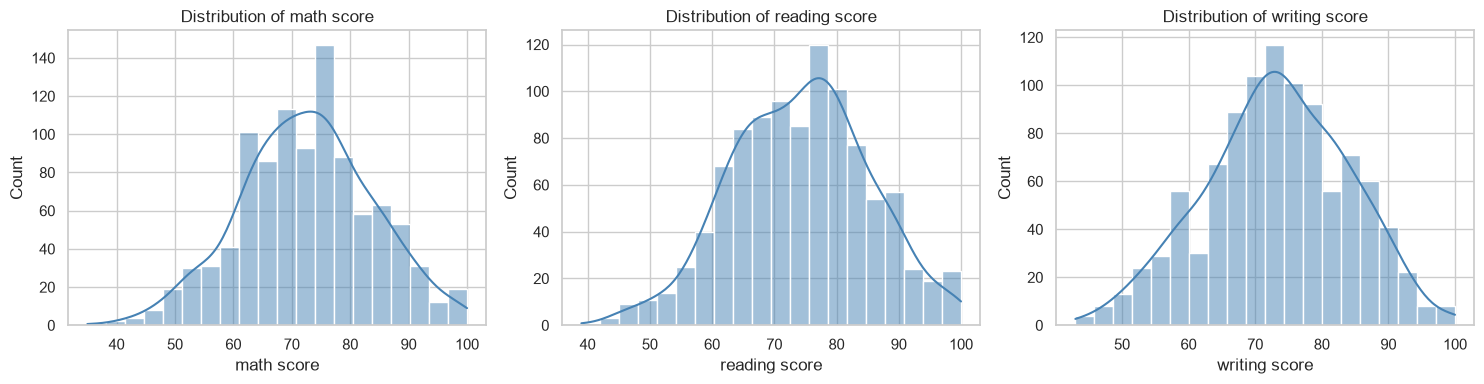

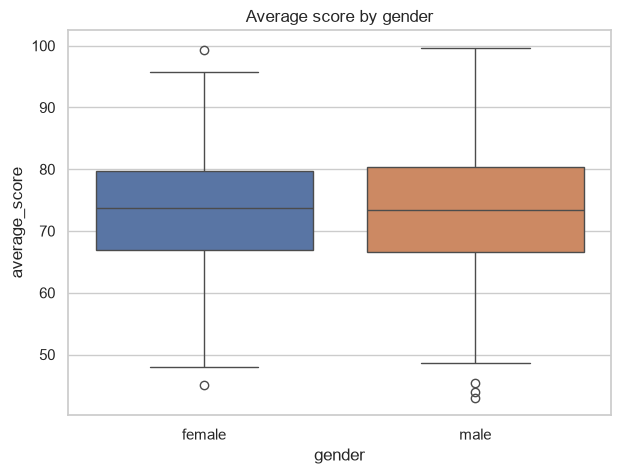

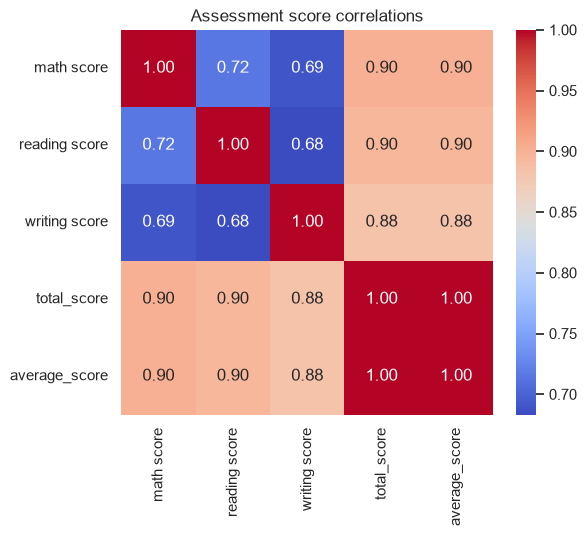

In [3]:
score_columns = ["math score", "reading score", "writing score"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4), tight_layout=True)
for ax, column in zip(axes, score_columns):
    sns.histplot(data=df, x=column, bins=20, kde=True, ax=ax, color="steelblue")
    ax.set_title(f"Distribution of {column}")
fig.savefig(images_dir / "score_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7, 5))
sns.boxplot(data=df, x="gender", y="average_score", hue="gender", legend=False, ax=ax)
ax.set_title("Average score by gender")
fig.savefig(images_dir / "average_score_by_gender.png", dpi=150, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(df[score_columns + ["total_score", "average_score"]].corr(), annot=True, cmap="coolwarm", fmt=".2f", ax=ax)
ax.set_title("Assessment score correlations")
fig.savefig(images_dir / "score_correlations.png", dpi=150, bbox_inches="tight")
plt.show()

In [4]:
categorical_features = [
    "gender",
    "race/ethnicity",
    "parental level of education",
    "lunch",
    "test preparation course",
]
X = df[categorical_features]
y = df["average_score"]

preprocessor = ColumnTransformer(
    transformers=[("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features)]
)
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", RandomForestRegressor(
            random_state=42,
            n_estimators=300,
            min_samples_leaf=3,
        )),
    ]
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
model.fit(X_train, y_train)
predictions = model.predict(X_test)
r2 = r2_score(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
print(f"R2 Score: {r2:.4f}")
print(f"RMSE: {rmse:.4f}")

R2 Score: 0.2691
RMSE: 8.6492
